<a href="https://colab.research.google.com/github/Rhema5/CSA47-Deep-Learning/blob/main/DL_LAB_PROG_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install tensorflow

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Optimizer: SGD
Test Loss: 0.33482542634010315
Test Accuracy: 0.8500000238418579

Optimizer: RMSprop
Test Loss: 0.28980210423469543
Test Accuracy: 0.8600000143051147

Optimizer: Adam
Test Loss: 0.2816634774208069
Test Accuracy: 0.8600000143051147


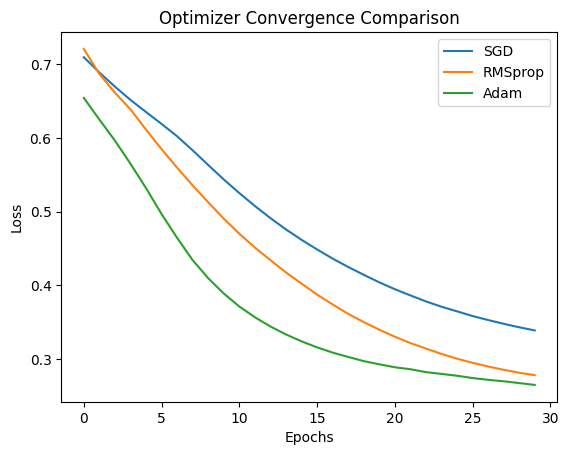

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD, RMSprop, Adam

X, y = make_moons(n_samples=500, noise=0.2, random_state=42)

X = StandardScaler().fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

optimizers = {
    'SGD': SGD(learning_rate=0.01),
    'RMSprop': RMSprop(learning_rate=0.001),
    'Adam': Adam(learning_rate=0.001)
}

for name, optimizer in optimizers.items():
    model = Sequential([
        Dense(16, activation='relu', input_shape=(2,)),
        Dense(8, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        X_train, y_train,
        epochs=30,
        batch_size=32,
        verbose=0
    )

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    print("\nOptimizer:", name)
    print("Test Loss:", loss)
    print("Test Accuracy:", accuracy)

    plt.plot(history.history['loss'], label=name)

plt.title("Optimizer Convergence Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train / 255.0
X_test = X_test / 255.0

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

predictions = model.predict(X_test[:5])
print("Predicted Digits:", np.argmax(predictions, axis=1))
print("Actual Digits:", np.argmax(y_test[:5], axis=1))


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9151 - loss: 0.2958 - val_accuracy: 0.9585 - val_loss: 0.1373
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.9653 - loss: 0.1147 - val_accuracy: 0.9743 - val_loss: 0.0872
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9783 - loss: 0.0709 - val_accuracy: 0.9735 - val_loss: 0.0819
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9839 - loss: 0.0518 - val_accuracy: 0.9792 - val_loss: 0.0748
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9874 - loss: 0.0402 - val_accuracy: 0.9782 - val_loss: 0.0763
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9771 - loss: 0.0787
Test Loss: 0.07871150225400925
Test Accuracy: 0.9771000146865845
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
Predicted Digits: [7 2 1 0 4]
Actual Digits: [7 2 1 0 4]


In [ ]:

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.utils import to_categorical

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

X_train = X_train / 255.0
X_test = X_test / 255.0

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

def create_model(use_dropout):
    layers = [
        Flatten(input_shape=(28, 28)),
        Dense(256, activation='relu')
    ]

    if use_dropout:
        layers.append(Dropout(0.5))

    layers.append(Dense(128, activation='relu'))

    if use_dropout:
        layers.append(Dropout(0.3))

    layers.append(Dense(10, activation='softmax'))

    model = Sequential(layers)

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

model1 = create_model(False)
model2 = create_model(True)

print("Training without Dropout")
model1.fit(X_train, y_train, epochs=5, batch_size=128, verbose=1)

print("\nTraining with Dropout")
model2.fit(X_train, y_train, epochs=5, batch_size=128, verbose=1)

loss1, acc1 = model1.evaluate(X_test, y_test, verbose=0)
loss2, acc2 = model2.evaluate(X_test, y_test, verbose=0)

print("\nWithout Dropout Accuracy:", acc1)
print("With Dropout Accuracy:", acc2)

print("Without Dropout Loss:", loss1)
print("With Dropout Loss:", loss2)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training without Dropout
Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.8207 - loss: 0.5095
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8659 - loss: 0.3695
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8799 - loss: 0.3303
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.8889 - loss: 0.3013
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8938 - loss: 0.2868

Training with Dropout
Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.7532 - loss: 0.6846
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8273 - loss: 0.4822
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8407 - loss: 0.4428
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8469 - loss: 0.4203
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8555 - loss: 0.3967

Without Dropout Accuracy: 0.8769999742507935
With Dropout Accuracy: 0.8665000200271606
Without D

In [ ]:

import numpy as np
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.regularizers import l2

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

X_train = X_train / 255.0
X_test = X_test / 255.0

def create_model(use_l2):
    regularizer = l2(0.01) if use_l2 else None

    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(128, activation='relu', kernel_regularizer=regularizer),
        Dense(64, activation='relu', kernel_regularizer=regularizer),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

model1 = create_model(False)
model2 = create_model(True)

model1.fit(X_train, y_train, epochs=5, batch_size=128, verbose=0)
model2.fit(X_train, y_train, epochs=5, batch_size=128, verbose=0)

loss1, acc1 = model1.evaluate(X_test, y_test, verbose=0)
loss2, acc2 = model2.evaluate(X_test, y_test, verbose=0)

print("Without L2 Regularization")
print("Accuracy:", acc1)
print("Loss:", loss1)

print("\nWith L2 Regularization")
print("Accuracy:", acc2)
print("Loss:", loss2)

print("\nWeight Magnitudes:")
print("Without L2:", np.mean(np.abs(model1.layers[1].get_weights()[0])))
print("With L2:", np.mean(np.abs(model2.layers[1].get_weights()[0])))


Without L2 Regularization
Accuracy: 0.8730999827384949
Loss: 0.3476579785346985

With L2 Regularization
Accuracy: 0.8241000175476074
Loss: 0.648369550704956

Weight Magnitudes:
Without L2: 0.057146616
With L2: 0.0050599803


In [ ]:

import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2

X, y = make_classification(
    n_samples=1000,
    n_features=20,
    n_informative=10,
    n_redundant=5,
    random_state=42
)

X = StandardScaler().fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

def create_model(regularized):
    if regularized:
        model = Sequential([
            Dense(64, activation='relu',
                  kernel_regularizer=l2(0.01), input_shape=(20,)),
            Dropout(0.3),
            Dense(32, activation='relu',
                  kernel_regularizer=l2(0.01)),
            Dense(1, activation='sigmoid')
        ])
    else:
        model = Sequential([
            Dense(64, activation='relu', input_shape=(20,)),
            Dense(32, activation='relu'),
            Dense(1, activation='sigmoid')
        ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

for name, regularized in [
    ("Without Regularization", False),
    ("With Regularization", True)
]:
    model = create_model(regularized)

    model.fit(X_train, y_train, epochs=30, verbose=0)

    train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

    print("\n", name)
    print("Training Accuracy:", train_acc)
    print("Testing Accuracy:", test_acc)
    print("Training Loss:", train_loss)
    print("Testing Loss:", test_loss)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



 Without Regularization
Training Accuracy: 0.9962499737739563
Testing Accuracy: 0.9350000023841858
Training Loss: 0.03318978473544121
Testing Loss: 0.13823452591896057

 With Regularization
Training Accuracy: 0.9637500047683716
Testing Accuracy: 0.9449999928474426
Training Loss: 0.24323008954524994
Testing Loss: 0.28274601697921753


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 56s 128ms/step - accuracy: 0.9369 - loss: 0.2191 - val_accuracy: 0.9815 - val_loss: 0.0612
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 105ms/step - accuracy: 0.9820 - loss: 0.0573 - val_accuracy: 0.9882 - val_loss: 0.0432
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 106ms/step - accuracy: 0.9871 - loss: 0.0397 - val_accuracy: 0.9893 - val_loss: 0.0390
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 106ms/step - accuracy: 0.9907 - loss: 0.0304 - val_accuracy: 0.9898 - val_loss: 0.0340
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 104ms/step - accuracy: 0.9926 - loss: 0.0238 - val_accuracy: 0.9907 - val_loss: 0.0360
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9900 - loss: 0.0308
Test Loss: 0.03082040138542652
Test Accuracy: 0.9900000095367432
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step


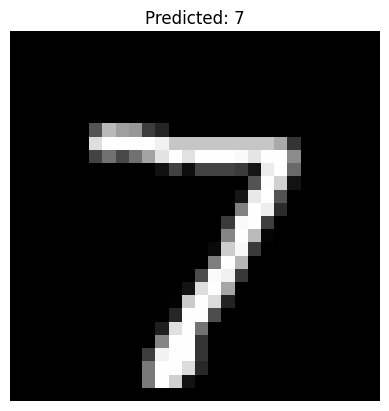

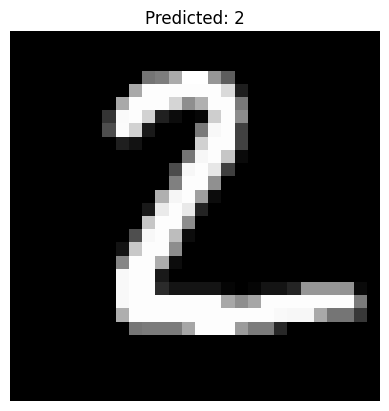

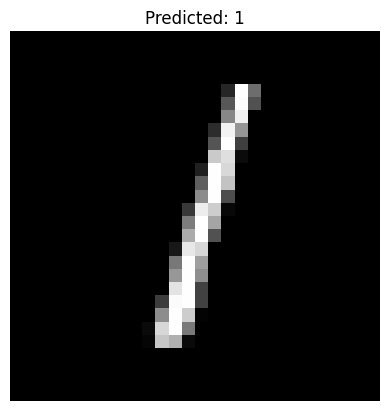

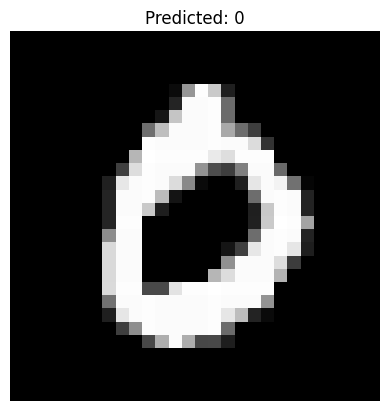

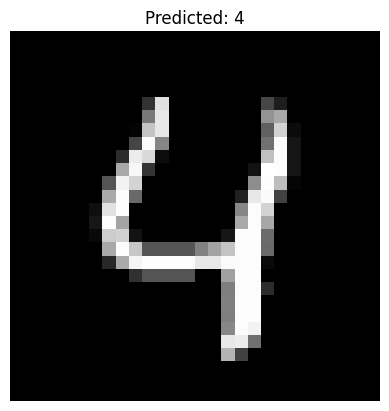

Actual Labels: [7 2 1 0 4]


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.reshape(-1, 28, 28, 1) / 255.0
X_test = X_test.reshape(-1, 28, 28, 1) / 255.0

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train, y_train, epochs=5, batch_size=128, validation_split=0.1)

loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

predictions = model.predict(X_test[:5])

for i in range(5):
    plt.imshow(X_test[i].squeeze(), cmap='gray')
    plt.title("Predicted: " + str(np.argmax(predictions[i])))
    plt.axis('off')
    plt.show()

print("Actual Labels:", y_test[:5])


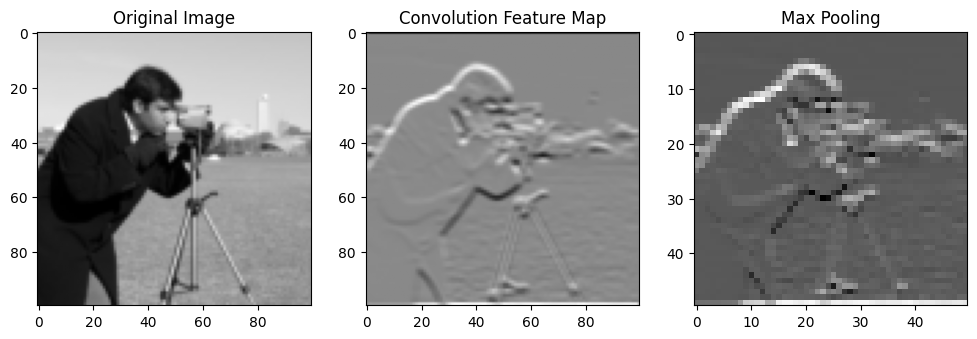

Original Image Shape: (100, 100)
Feature Map Shape: (100, 100)
Pooled Image Shape: (50, 50)


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d
from skimage.data import camera
from skimage.transform import resize

image = resize(camera(), (100, 100))

kernel = np.array([
    [-1, -1, -1],
    [0, 0, 0],
    [1, 1, 1]
])

feature_map = convolve2d(image, kernel, mode='same')

pooled = np.zeros((50, 50))

for i in range(50):
    for j in range(50):
        pooled[i, j] = np.max(
            feature_map[i*2:i*2+2, j*2:j*2+2]
        )

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")

plt.subplot(1, 3, 2)
plt.imshow(feature_map, cmap='gray')
plt.title("Convolution Feature Map")

plt.subplot(1, 3, 3)
plt.imshow(pooled, cmap='gray')
plt.title("Max Pooling")

plt.show()

print("Original Image Shape:", image.shape)
print("Feature Map Shape:", feature_map.shape)
print("Pooled Image Shape:", pooled.shape)


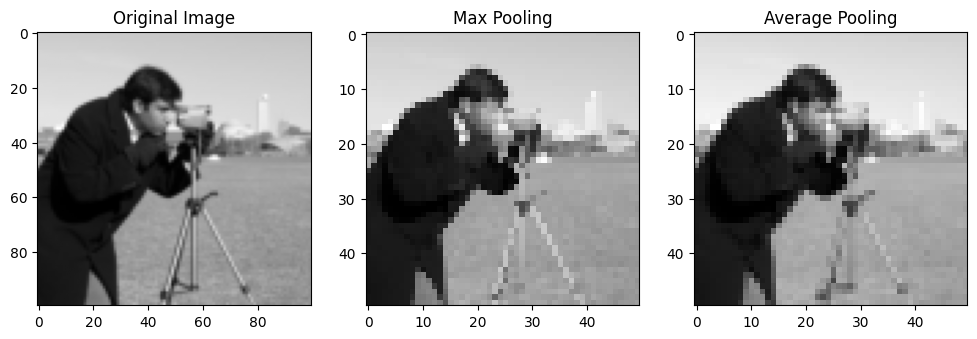

Original Shape: (100, 100)
Max Pooling Shape: (50, 50)
Average Pooling Shape: (50, 50)


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from skimage.data import camera
from skimage.transform import resize

image = resize(camera(), (100, 100))

max_pool = np.zeros((50, 50))
avg_pool = np.zeros((50, 50))

for i in range(50):
    for j in range(50):
        region = image[i*2:i*2+2, j*2:j*2+2]

        max_pool[i, j] = np.max(region)
        avg_pool[i, j] = np.mean(region)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")

plt.subplot(1, 3, 2)
plt.imshow(max_pool, cmap='gray')
plt.title("Max Pooling")

plt.subplot(1, 3, 3)
plt.imshow(avg_pool, cmap='gray')
plt.title("Average Pooling")

plt.show()

print("Original Shape:", image.shape)
print("Max Pooling Shape:", max_pool.shape)
print("Average Pooling Shape:", avg_pool.shape)


In [ ]:

import numpy as np
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

(X_train, y_train), (X_test, y_test) = cifar10.load_data()

train_mask = np.isin(y_train.flatten(), [3, 5])
test_mask = np.isin(y_test.flatten(), [3, 5])

X_train = X_train[train_mask][:4000] / 255.0
y_train = (y_train.flatten()[train_mask][:4000] == 5).astype(int)

X_test = X_test[test_mask][:1000] / 255.0
y_test = (y_test.flatten()[test_mask][:1000] == 5).astype(int)

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train, y_train, epochs=5, batch_size=64)

loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

predictions = model.predict(X_test[:5])

for i in range(5):
    print("Prediction:", "Dog" if predictions[i][0] >= 0.5 else "Cat")
    print("Actual:", "Dog" if y_test[i] == 1 else "Cat")


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 550s 3us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.5587 - loss: 0.6852
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 0.6083 - loss: 0.6580
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 97ms/step - accuracy: 0.6637 - loss: 0.6221
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.6855 - loss: 0.5951
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step - accuracy: 0.7038 - loss: 0.5694
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.6220 - loss: 0.6323
Test Loss: 0.6322863698005676
Test Accuracy: 0.621999979019165
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
Prediction: Dog
Actual: Cat
Prediction: Cat
Actual: Cat
Prediction: Dog
Actual: Dog
Prediction: Dog
Actual: Dog
Prediction: Dog
Actual: Dog


In [ ]:

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train[:10000].reshape(-1, 28, 28, 1) / 255.0
X_test = X_test[:2000].reshape(-1, 28, 28, 1) / 255.0

y_train = y_train[:10000]
y_test = y_test[:2000]

configurations = [
    (16, (3, 3)),
    (32, (3, 3)),
    (32, (5, 5)),
    (64, (5, 5))
]

for filters, kernel_size in configurations:
    model = Sequential([
        Conv2D(filters, kernel_size, activation='relu',
               input_shape=(28, 28, 1)),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    model.fit(X_train, y_train, epochs=2, batch_size=128, verbose=0)

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    print("\nFilters:", filters)
    print("Filter Size:", kernel_size)
    print("Test Accuracy:", accuracy)
    print("Test Loss:", loss)



Filters: 16
Filter Size: (3, 3)
Test Accuracy: 0.9154999852180481
Test Loss: 0.2858942449092865

Filters: 32
Filter Size: (3, 3)
Test Accuracy: 0.8870000243186951
Test Loss: 0.3531370759010315

Filters: 32
Filter Size: (5, 5)
Test Accuracy: 0.9265000224113464
Test Loss: 0.23600448668003082

Filters: 64
Filter Size: (5, 5)
Test Accuracy: 0.940500020980835
Test Loss: 0.20997507870197296


In [ ]:

import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, confusion_matrix

np.random.seed(42)

X = []
y = []

for i in range(500):
    image = np.random.rand(28, 28, 1) * 0.1

    if i % 2 == 0:
        image[10:18, 10:18, 0] += 0.8
        y.append(1)
    else:
        y.append(0)

    X.append(image)

X = np.array(X)
y = np.array(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = Sequential([
    Conv2D(16, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train, y_train, epochs=5, verbose=0)

predictions = (model.predict(X_test) >= 0.5).astype(int).flatten()

print("Accuracy:", accuracy_score(y_test, predictions))
print("Precision:", precision_score(y_test, predictions))
print("Recall:", recall_score(y_test, predictions))
print("F1 Score:", f1_score(y_test, predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Confusion Matrix:
[[50  0]
 [ 0 50]]


In [ ]:

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten
from tensorflow.keras.layers import Dense, BatchNormalization

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train[:10000].reshape(-1, 28, 28, 1) / 255.0
X_test = X_test[:2000].reshape(-1, 28, 28, 1) / 255.0

y_train = y_train[:10000]
y_test = y_test[:2000]

def create_model(use_bn):
    model = Sequential()

    model.add(Conv2D(32, (3, 3), activation='relu',
                     input_shape=(28, 28, 1)))

    if use_bn:
        model.add(BatchNormalization())

    model.add(MaxPooling2D((2, 2)))
    model.add(Flatten())
    model.add(Dense(64, activation='relu'))

    if use_bn:
        model.add(BatchNormalization())

    model.add(Dense(10, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

for name, use_bn in [
    ("Without Batch Normalization", False),
    ("With Batch Normalization", True)
]:
    model = create_model(use_bn)

    history = model.fit(
        X_train, y_train,
        epochs=5,
        batch_size=128,
        verbose=0
    )

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    print("\n", name)
    print("Test Loss:", loss)
    print("Test Accuracy:", accuracy)
    print("Final Training Loss:", history.history['loss'][-1])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



 Without Batch Normalization
Test Loss: 0.1822301149368286
Test Accuracy: 0.9455000162124634
Final Training Loss: 0.10132303833961487

 With Batch Normalization
Test Loss: 1.4796687364578247
Test Accuracy: 0.4424999952316284
Final Training Loss: 0.013417262583971024


In [ ]:

import numpy as np
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train[:10000].reshape(-1, 28, 28, 1) / 255.0
X_test = X_test[:2000].reshape(-1, 28, 28, 1) / 255.0

y_train = y_train[:10000]
y_test = y_test[:2000]

def create_model():
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu',
               input_shape=(28, 28, 1)),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

model1 = create_model()

model1.fit(X_train, y_train, epochs=5, batch_size=128, verbose=0)

loss1, acc1 = model1.evaluate(X_test, y_test, verbose=0)

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=False
)

model2 = create_model()

model2.fit(
    datagen.flow(X_train, y_train, batch_size=128),
    epochs=5,
    steps_per_epoch=len(X_train) // 128,
    verbose=0
)

loss2, acc2 = model2.evaluate(X_test, y_test, verbose=0)

print("Without Augmentation Accuracy:", acc1)
print("With Augmentation Accuracy:", acc2)

print("Without Augmentation Loss:", loss1)
print("With Augmentation Loss:", loss2)


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Without Augmentation Accuracy: 0.9539999961853027
With Augmentation Accuracy: 0.9304999709129333
Without Augmentation Loss: 0.1557973176240921
With Augmentation Loss: 0.23031915724277496


In [ ]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense

(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# Use a smaller dataset for demonstration
X_train = X_train[:2000]
y_train = y_train[:2000]

X_test = X_test[:500]
y_test = y_test[:500]

# Resize images for ResNet50
X_train = tf.image.resize(X_train, (96, 96)).numpy()
X_test = tf.image.resize(X_test, (96, 96)).numpy()

X_train = preprocess_input(X_train)
X_test = preprocess_input(X_test)

base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

base_model.trainable = False

model = Sequential([
    Input(shape=(96, 96, 3)),
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=32,
    validation_split=0.1
)

loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

predictions = model.predict(X_test[:5])

print("Predicted Classes:", np.argmax(predictions, axis=1))
print("Actual Classes:", y_test[:5].flatten())


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
57/57 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - accuracy: 0.6844 - loss: 1.1084 - val_accuracy: 0.8350 - val_loss: 0.5006
Epoch 2/3
57/57 ━━━━━━━━━━━━━━━━━━━━ 74s 1s/step - accuracy: 0.9028 - loss: 0.3024 - val_accuracy: 0.8550 - val_loss: 0.4453
Epoch 3/3
57/57 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.9622 - loss: 0.1329 - val_accuracy: 0.8750 - val_loss: 0.4600
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.7820 - loss: 0.6717
Test Loss: 0.6717336177825928
Test Accuracy: 0.7820000052452087


1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
Predicted Classes: [3 8 8 0 6]
Actual Classes: [3 8 8 0 6]


In [ ]:

import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

np.random.seed(42)

# Generate sequential sensor readings
data = np.sin(np.arange(0, 1000) * 0.05)

X = []
y = []

for i in range(len(data) - 10):
    X.append(data[i:i+10])
    y.append(data[i+10])

X = np.array(X).reshape(-1, 10, 1)
y = np.array(y)

model = Sequential([
    SimpleRNN(32, activation='tanh', input_shape=(10, 1)),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mse'
)

model.fit(X, y, epochs=10, batch_size=32, verbose=1)

predictions = model.predict(X[:5])

print("Actual Sensor Values:")
print(y[:5])

print("\nPredicted Sensor Values:")
print(predictions.flatten())


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.4089
Epoch 2/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0113
Epoch 3/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0036
Epoch 4/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0027
Epoch 5/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0022
Epoch 6/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0019
Epoch 7/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0016
Epoch 8/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0013
Epoch 9/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0012
Epoch 10/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
Actual Sensor Values:
[0.47942554 0.52268723 0.56464247 0.60518641 0.64421769]

Predicted Sensor Values:
[0.5182818  0.5576252  0.5940875  0.62782276 0.65908647]


Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1467
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0349 
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0169 
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0085 
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0067 
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0049 
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0037 
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0033 
Epoch 9/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0033 
Epoch 10/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0032 
Epoch 11/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0030 
Epoch 12/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0028 
Epoch 13/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0027 
Epoch 14/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0027 
Epoch 15/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0026 
Epoch 16/20
10/1

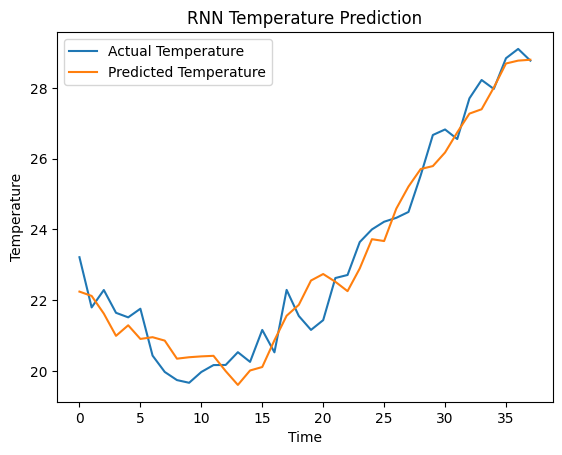

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

np.random.seed(42)

# Generate temperature observations
temperature = 25 + 5 * np.sin(np.arange(200) * 0.1)
temperature += np.random.normal(0, 0.5, 200)

scaler = MinMaxScaler()

data = scaler.fit_transform(
    temperature.reshape(-1, 1)
)

X = []
y = []

for i in range(10, len(data)):
    X.append(data[i-10:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(len(X) * 0.8)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

model = Sequential([
    SimpleRNN(32, activation='tanh', input_shape=(10, 1)),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mse'
)

model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=16,
    verbose=1
)

predictions = model.predict(X_test)

predictions = scaler.inverse_transform(predictions)
actual = scaler.inverse_transform(y_test)

mse = mean_squared_error(actual, predictions)

print("Actual Temperatures:")
print(actual[:10].flatten())

print("\nPredicted Temperatures:")
print(predictions[:10].flatten())

print("\nMean Squared Error:", mse)

plt.plot(actual, label='Actual Temperature')
plt.plot(predictions, label='Predicted Temperature')

plt.title("RNN Temperature Prediction")
plt.xlabel("Time")
plt.ylabel("Temperature")
plt.legend()
plt.show()
